Name :- Abhijeet Dinakar Pathade

Roll_No :- 16

Division :- AIML(A)

# Experiment No. 10 — Implementation of Non-Linear SVM

## Counterfeit Banknote Detection using Non-Linear SVM

### Problem Statement

Develop a Non-Linear Support Vector Machine (SVM) classification model using the Radial Basis Function (RBF) kernel to learn a non-linear decision boundary from labelled banknote samples and classify banknotes as genuine or counterfeit. Deploy the trained model as a web application using Flask and HTML.

### Objective
Use the Banknote Authentication dataset to predict whether a banknote is **genuine or counterfeit** using four numerical features extracted from its image:

- Variance
- Skewness
- Curtosis
- Entropy

**Algorithm:** Non-Linear Support Vector Machine (SVM) with the RBF kernel  
**Dataset:** `data_banknote_authentication.csv`

> You can reuse the same dataset used for Linear SVM. The main change is the non-linear RBF kernel.

## 1. Import Libraries

Import the libraries needed for data handling, visualization, model training, evaluation, and saving the trained model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Banknote Authentication Dataset from Google Drive

Upload `data_banknote_authentication.csv` to the top level of **My Drive**. If you save it in a folder, update `file_path` accordingly.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_path = "/content/drive/MyDrive/data_banknote_authentication.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## 3. Inspect the Dataset

The dataset contains four numerical input features and a target column named `class`. In the commonly used dataset encoding, class `0` represents genuine banknotes and class `1` represents counterfeit banknotes.

In [4]:
df.columns = [col.strip().lower() for col in df.columns]

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

print("\nTotal records:", len(df))

Column names:
['variance', 'skewness', 'curtosis', 'entropy', 'class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Total records: 1372


## 4. Visualize the Class Distribution

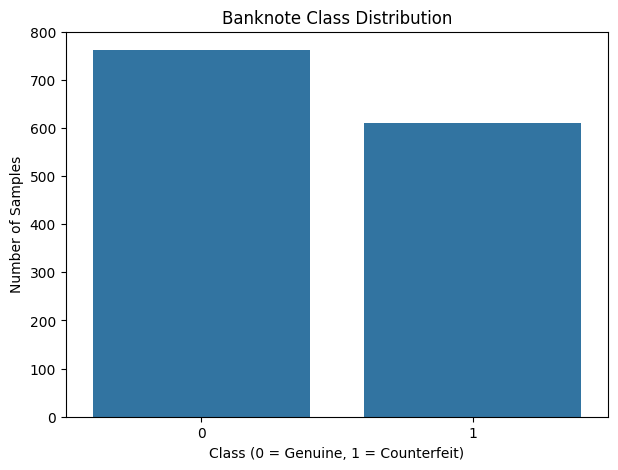

In [5]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="class")
plt.title("Banknote Class Distribution")
plt.xlabel("Class (0 = Genuine, 1 = Counterfeit)")
plt.ylabel("Number of Samples")
plt.show()

## 5. Prepare Features and Target

`X` contains the four numerical measurements. `y` contains the class label to predict.

In [6]:
feature_columns = ["variance", "skewness", "curtosis", "entropy"]
X = df[feature_columns]
y = df["class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1372, 4)
Target shape: (1372,)


## 6. Split the Dataset

Use a stratified 80:20 train-test split so both sets retain approximately the same class proportions. A fixed random state makes the split reproducible.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


## 7. Build and Train the Non-Linear SVM Model

The **RBF (Radial Basis Function) kernel** lets the SVM learn a non-linear decision boundary. `StandardScaler` is inside the pipeline so scaling is fitted only on training data.

In [8]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

model.fit(X_train, y_train)
print("Non-Linear SVM model trained successfully!")

Non-Linear SVM model trained successfully!


## 8. Evaluate the Model

In [9]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Genuine (0)", "Counterfeit (1)"],
    zero_division=0
))

Test Accuracy: 100.00%

Classification Report:
                 precision    recall  f1-score   support

    Genuine (0)       1.00      1.00      1.00       153
Counterfeit (1)       1.00      1.00      1.00       122

       accuracy                           1.00       275
      macro avg       1.00      1.00      1.00       275
   weighted avg       1.00      1.00      1.00       275



## 9. Display the Confusion Matrix

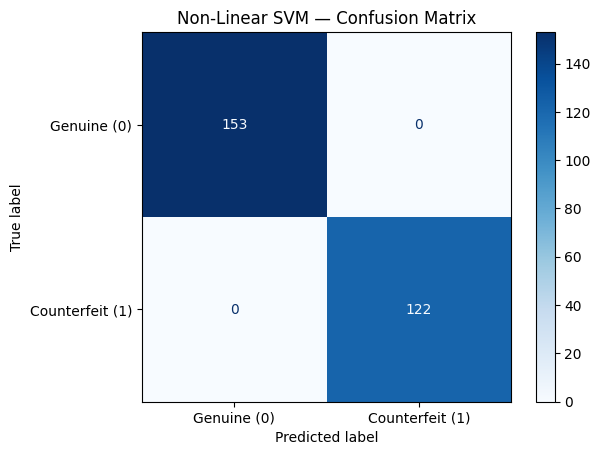

In [10]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine (0)", "Counterfeit (1)"]
)
display.plot(cmap="Blues", values_format="d")
plt.title("Non-Linear SVM — Confusion Matrix")
plt.show()

## 10. Predict a New Banknote Sample

The values below are an example. Replace them with the feature values you want to test.

In [12]:
sample = pd.DataFrame([{
    "variance": 3.6216,
    "skewness": 8.6661,
    "curtosis": -2.8073,
    "entropy": -0.44699
}])

prediction = model.predict(sample)[0]
label = "Genuine Banknote" if prediction == 0 else "Counterfeit Banknote"

print("Input sample:")
print(sample)
print("Predicted class:", prediction)
print("Prediction:", label)

Input sample:
   variance  skewness  curtosis  entropy
0    3.6216    8.6661   -2.8073 -0.44699
Predicted class: 0
Prediction: Genuine Banknote


## 11. Save the Trained Model

Save the complete pipeline (scaler + SVM) so Flask can load it and make predictions using the same preprocessing.

In [14]:
joblib.dump(model, "nonlinear_svm_banknote_model.pkl")
print("Saved: nonlinear_svm_banknote_model.pkl")

Saved: nonlinear_svm_banknote_model.pkl


## 12. Download the Trained Model

In [15]:
from google.colab import files
files.download("nonlinear_svm_banknote_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

####**Flask Code :-**

In [ ]:

from flask import Flask, render_template, request
import joblib
import pandas as pd

app = Flask(__name__)

# Load the trained Non-Linear SVM pipeline
model = joblib.load("nonlinear_svm_banknote_model.pkl")


@app.route("/", methods=["GET", "POST"])
def home():
    prediction = None
    error = None
    values = {
        "variance": "",
        "skewness": "",
        "curtosis": "",
        "entropy": ""
    }

    if request.method == "POST":
        try:
            for feature in values:
                values[feature] = request.form.get(feature, "").strip()
                if not values[feature]:
                    raise ValueError("Please enter all four feature values.")

            sample = pd.DataFrame([{
                "variance": float(values["variance"]),
                "skewness": float(values["skewness"]),
                "curtosis": float(values["curtosis"]),
                "entropy": float(values["entropy"])
            }])

            result = int(model.predict(sample)[0])

            if result == 0:
                prediction = "Genuine Banknote"
            else:
                prediction = "Counterfeit Banknote"

        except ValueError as e:
            error = str(e) or "Please enter valid numerical values."
        except Exception:
            error = "Prediction failed. Check the input values and trained model."

    return render_template(
        "index.html",
        prediction=prediction,
        error=error,
        values=values
    )


if __name__ == "__main__":
    app.run(debug=True)


#### **HTML Code :-**

In [ ]:

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Banknote Authentication | Non-Linear SVM</title>

    <style>
        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            padding: 30px 15px;
            font-family: Arial, sans-serif;
            background: linear-gradient(135deg, #e0eafc, #cfdef3);
            color: #243047;
        }

        .container {
            max-width: 650px;
            margin: 20px auto;
            padding: 30px;
            background: white;
            border-radius: 16px;
            box-shadow: 0 8px 25px rgba(0, 0, 0, 0.12);
        }

        h1 {
            text-align: center;
            margin-bottom: 8px;
            color: #173b70;
        }

        .subtitle {
            text-align: center;
            color: #64748b;
            margin-bottom: 28px;
        }

        .field {
            margin-bottom: 18px;
        }

        label {
            display: block;
            margin-bottom: 7px;
            font-weight: bold;
        }

        input {
            width: 100%;
            padding: 12px;
            border: 1px solid #cbd5e1;
            border-radius: 8px;
            font-size: 16px;
        }

        input:focus {
            outline: 2px solid #7da9ef;
            border-color: #2563eb;
        }

        button {
            width: 100%;
            padding: 14px;
            border: none;
            border-radius: 8px;
            background: #2458a6;
            color: white;
            font-size: 16px;
            font-weight: bold;
            cursor: pointer;
        }

        button:hover {
            background: #173b70;
        }

        .result {
            margin-top: 24px;
            padding: 16px;
            text-align: center;
            border-radius: 8px;
            font-size: 18px;
            font-weight: bold;
        }

        .genuine {
            background: #dcfce7;
            color: #166534;
        }

        .counterfeit {
            background: #fee2e2;
            color: #991b1b;
        }

        .error {
            background: #fff7ed;
            color: #9a3412;
        }

        .note {
            margin-top: 22px;
            font-size: 13px;
            line-height: 1.6;
            color: #64748b;
            text-align: center;
        }
    </style>
</head>

<body>
    <div class="container">
        <h1>Banknote Authentication</h1>
        <p class="subtitle">
            Non-Linear SVM Classification using the RBF Kernel
        </p>

        <form method="POST">
            <div class="field">
                <label for="variance">Variance</label>
                <input type="number" step="any" id="variance"
                       name="variance" required
                       value="{{ values.variance }}">
            </div>

            <div class="field">
                <label for="skewness">Skewness</label>
                <input type="number" step="any" id="skewness"
                       name="skewness" required
                       value="{{ values.skewness }}">
            </div>

            <div class="field">
                <label for="curtosis">Curtosis</label>
                <input type="number" step="any" id="curtosis"
                       name="curtosis" required
                       value="{{ values.curtosis }}">
            </div>

            <div class="field">
                <label for="entropy">Entropy</label>
                <input type="number" step="any" id="entropy"
                       name="entropy" required
                       value="{{ values.entropy }}">
            </div>

            <button type="submit">Predict Banknote</button>
        </form>

        {% if prediction %}
            <div class="result
                {% if prediction == 'Genuine Banknote' %}
                    genuine
                {% else %}
                    counterfeit
                {% endif %}">
                Prediction: {{ prediction }}
            </div>
        {% endif %}

        {% if error %}
            <div class="result error">{{ error }}</div>
        {% endif %}

        <p class="note">
            This application uses a trained Non-Linear SVM model.
            The prediction is a machine-learning estimate and does
            not guarantee the authenticity of a physical banknote.
        </p>
    </div>
</body>
</html>

## 12. Conclusion

The Non-Linear SVM model was trained on the Banknote Authentication dataset using an RBF kernel. Its performance was evaluated using accuracy, a classification report, and a confusion matrix. The trained pipeline was saved as `nonlinear_svm_banknote_model.pkl` for later use in a Flask web application.
